# Breast Cancer Winsconsin (Diagnostic)
Classify a tumor as malignant or benign based on the features in the dataset

In [27]:
from ucimlrepo import fetch_ucirepo 
import pandas as pd
import sklearn
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras.models import Sequential
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

## Data Loading

In [28]:
# fetch dataset 
breast_cancer_wisconsin_diagnostic = fetch_ucirepo(id=17) 

X = breast_cancer_wisconsin_diagnostic.data.features
y = breast_cancer_wisconsin_diagnostic.data.targets

# M = 1, B = 0
y = y["Diagnosis"].map({"B": 0, "M": 1}).to_frame()

In [29]:
# features
X.head()

,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,radius3,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [30]:
# targets
y.head()

,Diagnosis
0,1
1,1
2,1
3,1
4,1


## Splitting into Training Data and Test Data

In [31]:
X_training, X_test, y_training, y_test = train_test_split(X, y, test_size=0.25)

In [32]:
X_training.shape, y_training.shape

((426, 30), (426, 1))

In [33]:
 X_test.shape, y_test.shape

((143, 30), (143, 1))

### Features Normalize

In [34]:
scaler = StandardScaler()
X_training = scaler.fit_transform(X_training)
X_test = scaler.transform(X_test)

## Neural Network Structure

We choose 16 neurons for hidden layer because the input layer has 30 neurons and the output layer has 1 neuron ( binary classification ). So, (30 + 1)/2 = 15.5 which approximated for 16.

Since this is a binary classification problem, we use the sigmoid activation function for the output layer.

In [35]:
neural_network = Sequential([
    tf.keras.Input(shape=(30,)),
    tf.keras.layers.Dense(units=16, activation='relu', kernel_initializer='random_uniform'),
    tf.keras.layers.Dense(units=1, activation='sigmoid')
])

neural_network.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 513 (2.00 KB)

 Trainable params: 513 (2.00 KB)

 Non-trainable params: 0 (0.00 B)

- 30 neurons in the input layer * 16 neurons in the hidden layer = 480 neurons 

    496 params - 480 = 16, which is the bias introduction in the hidden layer

- 17 params = 16 neurons in hidden layer connected in a only neuron of output + a bias

### Representation

```mermaid
graph TB
    classDef neuron fill:#ffffff,stroke:#333333,stroke-width:1px,color:#000000;
    classDef out fill:#d4edda,stroke:#333333,stroke-width:1.5px,color:#000000;

    subgraph IN["Entrada (30)"]
        X1((x1)):::neuron
        X2((x2)):::neuron
        X3((x3)):::neuron
        X4((x4)):::neuron
        X5((x5)):::neuron
        X6((x6)):::neuron
        X7((x7)):::neuron
        X8((x8)):::neuron
        X9((x9)):::neuron
        X10((x10)):::neuron
        X11((x11)):::neuron
        X12((x12)):::neuron
        X13((x13)):::neuron
        X14((x14)):::neuron
        X15((x15)):::neuron
        X16((x16)):::neuron
        X17((x17)):::neuron
        X18((x18)):::neuron
        X19((x19)):::neuron
        X20((x20)):::neuron
        X21((x21)):::neuron
        X22((x22)):::neuron
        X23((x23)):::neuron
        X24((x24)):::neuron
        X25((x25)):::neuron
        X26((x26)):::neuron
        X27((x27)):::neuron
        X28((x28)):::neuron
        X29((x29)):::neuron
        X30((x30)):::neuron
    end

    subgraph HID["Dense 16 · ReLU"]
        H1((h1)):::neuron
        H2((h2)):::neuron
        H3((h3)):::neuron
        H4((h4)):::neuron
        H5((h5)):::neuron
        H6((h6)):::neuron
        H7((h7)):::neuron
        H8((h8)):::neuron
        H9((h9)):::neuron
        H10((h10)):::neuron
        H11((h11)):::neuron
        H12((h12)):::neuron
        H13((h13)):::neuron
        H14((h14)):::neuron
        H15((h15)):::neuron
        H16((h16)):::neuron
    end

    subgraph OUT["Dense 1 · Sigmoid"]
        Y((y)):::out
    end

    %% Entrada -> Oculta: 480 conexões (entrada i usa links (i-1)*16 até i*16-1)
    X1 --> H1 & H2 & H3 & H4 & H5 & H6 & H7 & H8 & H9 & H10 & H11 & H12 & H13 & H14 & H15 & H16
    X2 --> H1 & H2 & H3 & H4 & H5 & H6 & H7 & H8 & H9 & H10 & H11 & H12 & H13 & H14 & H15 & H16
    X3 --> H1 & H2 & H3 & H4 & H5 & H6 & H7 & H8 & H9 & H10 & H11 & H12 & H13 & H14 & H15 & H16
    X4 --> H1 & H2 & H3 & H4 & H5 & H6 & H7 & H8 & H9 & H10 & H11 & H12 & H13 & H14 & H15 & H16
    X5 --> H1 & H2 & H3 & H4 & H5 & H6 & H7 & H8 & H9 & H10 & H11 & H12 & H13 & H14 & H15 & H16
    X6 --> H1 & H2 & H3 & H4 & H5 & H6 & H7 & H8 & H9 & H10 & H11 & H12 & H13 & H14 & H15 & H16
    X7 --> H1 & H2 & H3 & H4 & H5 & H6 & H7 & H8 & H9 & H10 & H11 & H12 & H13 & H14 & H15 & H16
    X8 --> H1 & H2 & H3 & H4 & H5 & H6 & H7 & H8 & H9 & H10 & H11 & H12 & H13 & H14 & H15 & H16
    X9 --> H1 & H2 & H3 & H4 & H5 & H6 & H7 & H8 & H9 & H10 & H11 & H12 & H13 & H14 & H15 & H16
    X10 --> H1 & H2 & H3 & H4 & H5 & H6 & H7 & H8 & H9 & H10 & H11 & H12 & H13 & H14 & H15 & H16
    X11 --> H1 & H2 & H3 & H4 & H5 & H6 & H7 & H8 & H9 & H10 & H11 & H12 & H13 & H14 & H15 & H16
    X12 --> H1 & H2 & H3 & H4 & H5 & H6 & H7 & H8 & H9 & H10 & H11 & H12 & H13 & H14 & H15 & H16
    X13 --> H1 & H2 & H3 & H4 & H5 & H6 & H7 & H8 & H9 & H10 & H11 & H12 & H13 & H14 & H15 & H16
    X14 --> H1 & H2 & H3 & H4 & H5 & H6 & H7 & H8 & H9 & H10 & H11 & H12 & H13 & H14 & H15 & H16
    X15 --> H1 & H2 & H3 & H4 & H5 & H6 & H7 & H8 & H9 & H10 & H11 & H12 & H13 & H14 & H15 & H16
    X16 --> H1 & H2 & H3 & H4 & H5 & H6 & H7 & H8 & H9 & H10 & H11 & H12 & H13 & H14 & H15 & H16
    X17 --> H1 & H2 & H3 & H4 & H5 & H6 & H7 & H8 & H9 & H10 & H11 & H12 & H13 & H14 & H15 & H16
    X18 --> H1 & H2 & H3 & H4 & H5 & H6 & H7 & H8 & H9 & H10 & H11 & H12 & H13 & H14 & H15 & H16
    X19 --> H1 & H2 & H3 & H4 & H5 & H6 & H7 & H8 & H9 & H10 & H11 & H12 & H13 & H14 & H15 & H16
    X20 --> H1 & H2 & H3 & H4 & H5 & H6 & H7 & H8 & H9 & H10 & H11 & H12 & H13 & H14 & H15 & H16
    X21 --> H1 & H2 & H3 & H4 & H5 & H6 & H7 & H8 & H9 & H10 & H11 & H12 & H13 & H14 & H15 & H16
    X22 --> H1 & H2 & H3 & H4 & H5 & H6 & H7 & H8 & H9 & H10 & H11 & H12 & H13 & H14 & H15 & H16
    X23 --> H1 & H2 & H3 & H4 & H5 & H6 & H7 & H8 & H9 & H10 & H11 & H12 & H13 & H14 & H15 & H16
    X24 --> H1 & H2 & H3 & H4 & H5 & H6 & H7 & H8 & H9 & H10 & H11 & H12 & H13 & H14 & H15 & H16
    X25 --> H1 & H2 & H3 & H4 & H5 & H6 & H7 & H8 & H9 & H10 & H11 & H12 & H13 & H14 & H15 & H16
    X26 --> H1 & H2 & H3 & H4 & H5 & H6 & H7 & H8 & H9 & H10 & H11 & H12 & H13 & H14 & H15 & H16
    X27 --> H1 & H2 & H3 & H4 & H5 & H6 & H7 & H8 & H9 & H10 & H11 & H12 & H13 & H14 & H15 & H16
    X28 --> H1 & H2 & H3 & H4 & H5 & H6 & H7 & H8 & H9 & H10 & H11 & H12 & H13 & H14 & H15 & H16
    X29 --> H1 & H2 & H3 & H4 & H5 & H6 & H7 & H8 & H9 & H10 & H11 & H12 & H13 & H14 & H15 & H16
    X30 --> H1 & H2 & H3 & H4 & H5 & H6 & H7 & H8 & H9 & H10 & H11 & H12 & H13 & H14 & H15 & H16

    %% Oculta -> Saída: 16 conexões (links 480-495)
    H1 --> Y
    H2 --> Y
    H3 --> Y
    H4 --> Y
    H5 --> Y
    H6 --> Y
    H7 --> Y
    H8 --> Y
    H9 --> Y
    H10 --> Y
    H11 --> Y
    H12 --> Y
    H13 --> Y
    H14 --> Y
    H15 --> Y
    H16 --> Y

    %% Uma cor por neurônio de entrada
    linkStyle 0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15 stroke:#df1f1f,stroke-width:0.6px;
    linkStyle 16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31 stroke:#df461f,stroke-width:0.6px;
    linkStyle 32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47 stroke:#df6c1f,stroke-width:0.6px;
    linkStyle 48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63 stroke:#df921f,stroke-width:0.6px;
    linkStyle 64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79 stroke:#dfb81f,stroke-width:0.6px;
    linkStyle 80,81,82,83,84,85,86,87,88,89,90,91,92,93,94,95 stroke:#dfdf1f,stroke-width:0.6px;
    linkStyle 96,97,98,99,100,101,102,103,104,105,106,107,108,109,110,111 stroke:#b8df1f,stroke-width:0.6px;
    linkStyle 112,113,114,115,116,117,118,119,120,121,122,123,124,125,126,127 stroke:#92df1f,stroke-width:0.6px;
    linkStyle 128,129,130,131,132,133,134,135,136,137,138,139,140,141,142,143 stroke:#6cdf1f,stroke-width:0.6px;
    linkStyle 144,145,146,147,148,149,150,151,152,153,154,155,156,157,158,159 stroke:#46df1f,stroke-width:0.6px;
    linkStyle 160,161,162,163,164,165,166,167,168,169,170,171,172,173,174,175 stroke:#1fdf1f,stroke-width:0.6px;
    linkStyle 176,177,178,179,180,181,182,183,184,185,186,187,188,189,190,191 stroke:#1fdf46,stroke-width:0.6px;
    linkStyle 192,193,194,195,196,197,198,199,200,201,202,203,204,205,206,207 stroke:#1fdf6c,stroke-width:0.6px;
    linkStyle 208,209,210,211,212,213,214,215,216,217,218,219,220,221,222,223 stroke:#1fdf92,stroke-width:0.6px;
    linkStyle 224,225,226,227,228,229,230,231,232,233,234,235,236,237,238,239 stroke:#1fdfb8,stroke-width:0.6px;
    linkStyle 240,241,242,243,244,245,246,247,248,249,250,251,252,253,254,255 stroke:#1fdfdf,stroke-width:0.6px;
    linkStyle 256,257,258,259,260,261,262,263,264,265,266,267,268,269,270,271 stroke:#1fb8df,stroke-width:0.6px;
    linkStyle 272,273,274,275,276,277,278,279,280,281,282,283,284,285,286,287 stroke:#1f92df,stroke-width:0.6px;
    linkStyle 288,289,290,291,292,293,294,295,296,297,298,299,300,301,302,303 stroke:#1f6cdf,stroke-width:0.6px;
    linkStyle 304,305,306,307,308,309,310,311,312,313,314,315,316,317,318,319 stroke:#1f46df,stroke-width:0.6px;
    linkStyle 320,321,322,323,324,325,326,327,328,329,330,331,332,333,334,335 stroke:#1f1fdf,stroke-width:0.6px;
    linkStyle 336,337,338,339,340,341,342,343,344,345,346,347,348,349,350,351 stroke:#461fdf,stroke-width:0.6px;
    linkStyle 352,353,354,355,356,357,358,359,360,361,362,363,364,365,366,367 stroke:#6c1fdf,stroke-width:0.6px;
    linkStyle 368,369,370,371,372,373,374,375,376,377,378,379,380,381,382,383 stroke:#921fdf,stroke-width:0.6px;
    linkStyle 384,385,386,387,388,389,390,391,392,393,394,395,396,397,398,399 stroke:#b81fdf,stroke-width:0.6px;
    linkStyle 400,401,402,403,404,405,406,407,408,409,410,411,412,413,414,415 stroke:#df1fdf,stroke-width:0.6px;
    linkStyle 416,417,418,419,420,421,422,423,424,425,426,427,428,429,430,431 stroke:#df1fb8,stroke-width:0.6px;
    linkStyle 432,433,434,435,436,437,438,439,440,441,442,443,444,445,446,447 stroke:#df1f92,stroke-width:0.6px;
    linkStyle 448,449,450,451,452,453,454,455,456,457,458,459,460,461,462,463 stroke:#df1f6c,stroke-width:0.6px;
    linkStyle 464,465,466,467,468,469,470,471,472,473,474,475,476,477,478,479 stroke:#df1f46,stroke-width:0.6px;

    %% Uma cor por neurônio oculto
    linkStyle 480 stroke:#a32828,stroke-width:2px;
    linkStyle 481 stroke:#a35628,stroke-width:2px;
    linkStyle 482 stroke:#a38428,stroke-width:2px;
    linkStyle 483 stroke:#93a328,stroke-width:2px;
    linkStyle 484 stroke:#66a328,stroke-width:2px;
    linkStyle 485 stroke:#38a328,stroke-width:2px;
    linkStyle 486 stroke:#28a347,stroke-width:2px;
    linkStyle 487 stroke:#28a375,stroke-width:2px;
    linkStyle 488 stroke:#28a3a3,stroke-width:2px;
    linkStyle 489 stroke:#2875a3,stroke-width:2px;
    linkStyle 490 stroke:#2847a3,stroke-width:2px;
    linkStyle 491 stroke:#3828a3,stroke-width:2px;
    linkStyle 492 stroke:#6528a3,stroke-width:2px;
    linkStyle 493 stroke:#9328a3,stroke-width:2px;
    linkStyle 494 stroke:#a32884,stroke-width:2px;
    linkStyle 495 stroke:#a32856,stroke-width:2px;


``` 

### Params Configuration

In [36]:
neural_network.compile(optimizer="adam", loss="binary_crossentropy", metrics=["binary_accuracy"])

In [37]:
neural_network.fit(X_training, y_training, batch_size=10, epochs=100)

Epoch 1/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - binary_accuracy: 0.8803 - loss: 0.4806  
Epoch 2/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.9366 - loss: 0.2596
Epoch 3/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.9484 - loss: 0.1820
Epoch 4/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.9624 - loss: 0.1439
Epoch 5/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.9718 - loss: 0.1220
Epoch 6/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.9742 - loss: 0.1079
Epoch 7/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.9812 - loss: 0.0985
Epoch 8/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.9836 - loss: 0.0908
Epoch 9/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.9836 - loss: 0.0858
Epoch 10/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.9836 - loss: 0.0818
Epoch 11/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.9836

The accuracy values ​​above are being calculated for the training set itself, which is not ideal. To do this correctly, we will use the test set.

In [38]:
predicteds = neural_network.predict(X_test)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 


In [39]:
predicteds

array([[2.06841520e-04],
       [1.00000000e+00],
       [4.14676060e-06],
       [8.56342922e-06],
       [1.00000000e+00],
       [1.00000000e+00],
       [1.62592997e-08],
       [1.00000000e+00],
       [1.00000000e+00],
       [1.00000000e+00],
       [1.00000000e+00],
       [7.38263056e-02],
       [1.00000000e+00],
       [2.39675160e-06],
       [1.00000000e+00],
       [9.99999523e-01],
       [3.45551098e-06],
       [1.50256608e-06],
       [4.97090891e-02],
       [4.20134427e-07],
       [7.44575300e-13],
       [1.00000000e+00],
       [1.18825515e-03],
       [1.00000000e+00],
       [9.99304295e-01],
       [1.00000000e+00],
       [3.50852963e-04],
       [1.47257117e-06],
       [1.85769983e-04],
       [2.92370707e-04],
       [1.00000000e+00],
       [9.31845477e-07],
       [1.00000000e+00],
       [3.98198469e-03],
       [8.43338016e-03],
       [8.06544995e-06],
       [2.31470484e-02],
       [9.94093163e-09],
       [5.14897227e-04],
       [7.63560965e-05],


In [40]:
predicteds = (neural_network.predict(X_test) > 0.5).astype(int)
predicteds

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 


array([[0],
       [1],
       [0],
       [0],
       [1],
       [1],
       [0],
       [1],
       [1],
       [1],
       [1],
       [0],
       [1],
       [0],
       [1],
       [1],
       [0],
       [0],
       [0],
       [0],
       [0],
       [1],
       [0],
       [1],
       [1],
       [1],
       [0],
       [0],
       [0],
       [0],
       [1],
       [0],
       [1],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [1],
       [0],
       [0],
       [1],
       [0],
       [1],
       [0],
       [0],
       [0],
       [0],
       [0],
       [1],
       [1],
       [0],
       [0],
       [0],
       [0],
       [0],
       [1],
       [1],
       [0],
       [1],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [1],
       [0],
       [1],
       [1],
    

In [41]:
accuracy_score(y_test, predicteds)

0.986013986013986

In [42]:
confusion_matrix = confusion_matrix(y_test, predicteds)

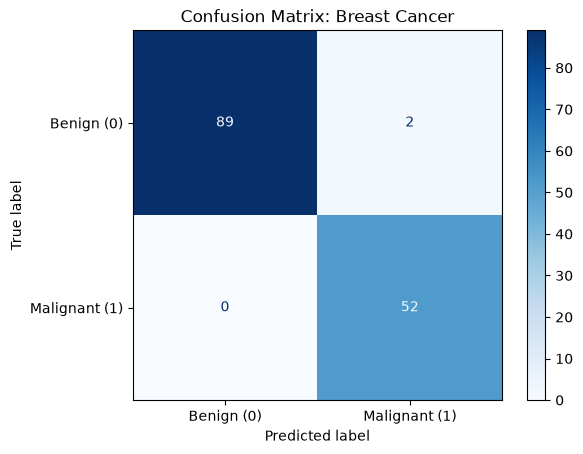

In [43]:
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix, display_labels=["Benign (0)", "Malignant (1)"])
disp.plot(cmap="Blues", values_format="d")

plt.title("Confusion Matrix: Breast Cancer")
plt.show()